# Week 8 - Linear Discriminant Analysis and Optimization

* FDA (2 classes)
    * Compute the class means (in PCA space)
    * Compute the within-class scatter matrix $\mathbf{S}_W$ and between-class scatter matrix $\mathbf{S}_B$
    * Compute the projection vector $\mathbf{w}$
    * Compute and plot the 1D projection of the data
    * Compute the class separation of the projected values
* LDA (3 classes)
    * Compute the within-class scatter matrix $\mathbf{S}_W$ and between-class scatter matrix $\mathbf{S}_B$
    * Compute the projection matrix $\mathbf{W}$
    * Compute and plot the 2D projection of the data
    * Compute the 2D LDA projection of the original 64D data 
* Constrained Optimization
    * Reformulate the problem as a maximization problem
    * Write out the Lagrangian function
    * Compute the gradients with respects to $x_1, x_2$, Lagrange multiplier $\lambda$ and the KKT multiplier $\mu$
    * Compute the optimum

In [1]:
# Dependencies
import numpy as np
import scipy
import scipy.linalg
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA 
import matplotlib.pyplot as plt 
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns; sns.set_theme(); sns.set_palette('bright')

## Data
As usual, we'll be working with a dataset of handwritten digits. 
Let visualise some examples.

In [2]:
# We're using a subset of two classes for now
digits = load_digits(n_class=2)

In [3]:
# Handy plotting functions

def plot_examples():
    show_num = 4
    _, axes = plt.subplots(1, show_num)
    images_and_labels = list(zip(digits.images, digits.target))
    for ax, (image, label) in zip(axes[:], images_and_labels[:show_num]):
        ax.set_axis_off()
        ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
        ax.set_title('Label: %i' % label)

def plot_scatter(data, target, alpha=0.5, legend=True,w=None):
    scatter = plt.scatter(data[:, 0], data[:, 1], c=target, edgecolor='none', alpha=alpha, cmap='rainbow')
    if legend:
        plt.legend(*scatter.legend_elements(), loc="upper right", title="Targets")
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')

    if w is not None:
        # w is a 2-D FDA direction vector (no bias term). The decision boundary
        # is the line perpendicular to w through the midpoint of the two class means.
        labels = np.unique(target)
        m1 = np.mean(data[target == labels[0]], axis=0)
        m2 = np.mean(data[target == labels[1]], axis=0)
        m_mid = (m1 + m2) / 2

        x_values = np.linspace(np.min(data[:, 0]), np.max(data[:, 0]), 100)
        # Perpendicular to w through m_mid: w[0]*(x - m_mid[0]) + w[1]*(y - m_mid[1]) = 0
        y_values = m_mid[1] - (w[0] / w[1]) * (x_values - m_mid[0])

        plt.plot(x_values, y_values, color='red', label='Decision boundary')
    #plt.show()
    
def plot_scatter3d(data, targets, view_point=(25, 45), alpha=0.5, legend=True):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(data[:,0], data[:,1], data[:,2], c=targets, cmap="rainbow", alpha=alpha)
    if legend:
        plt.legend(*scatter.legend_elements(), loc="upper right", title="Targets")
    ax.view_init(*view_point) # <- change viewpoint here
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')
    ax.set_zlabel('Component 3')
    plt.show()

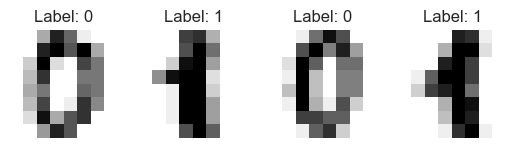

In [4]:
plot_examples()

In [5]:
# We can get a 2D version of the data using PCA
pca = PCA(n_components=2)
X = pca.fit_transform(digits.data) # this is the representation, we'll be working with
t = digits.target

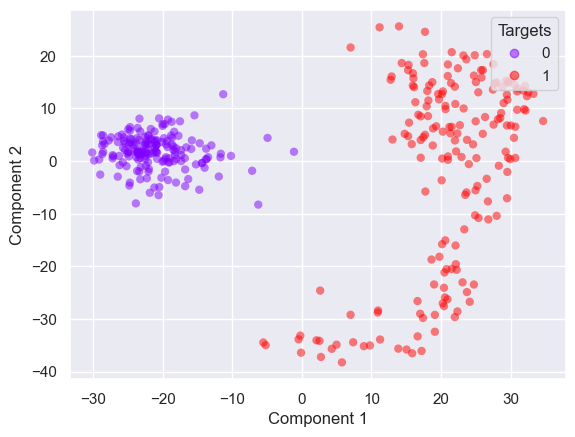

In [6]:
# Let's plot all the data in 2D
plot_scatter(X, t)

## 1) Fisher Discriminant Analysis (FDA)


### 1.1) Compute the class means (in PCA space)

In [7]:
# X shape: (N, 2), t shape: (N,); classes are labelled 0 and 1
# TODO: compute the mean of each class -> m shape: (2, 2), where row m[k] (shape (2,)) is the mean of class k
mask_0 = (t == 0)
class_0 = X[mask_0] # Data points in class 0, (# in class 0, 2)
mean_0 = np.mean(class_0, axis=0) # we average down the rows (2, )

mask_1 = (t == 1)
class_1 = X[mask_1] # Data points in class 0, (# in class 0, 2)
mean_1 = np.mean(class_1, axis=0) # we average down the rows (2, )

means = np.array([mean_0, mean_1])
print(mean_0.shape)

print("Mean for class 0: ", means[0])
print("Mean for class 1: ", means[1])

(2,)
Mean for class 0:  [-21.14447038   1.75335626]
Mean for class 1:  [20.67975675 -1.71482096]


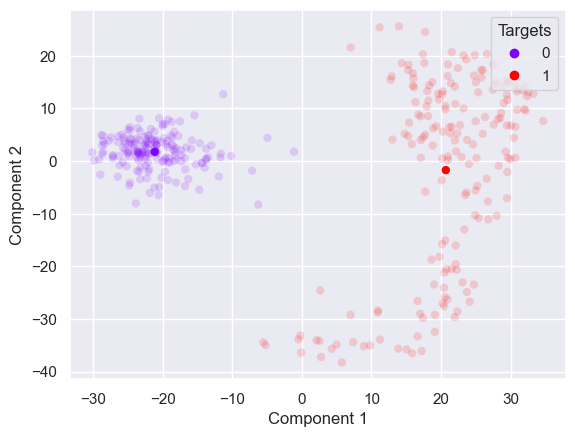

In [8]:
# Extra reference plot: class means over the faded PCA data (PDF page 2).
plt.figure()
plot_scatter(X, t, alpha=0.15, legend=False)
plot_scatter(means, np.array([0, 1]), alpha=1)
plt.show()


### 1.2) Compute the within-class scatter matrix $\mathbf{S}_W$ and between-class scatter matrix $\mathbf{S}_B$
Use eq (4.27) and (4.28) from textbook for computing $\mathbf{S}_B$ and $\mathbf{S}_W$ respectively

In [9]:
# X shape: (N, 2), t shape: (N,), m[k] shape: (2,)
# TODO: compute S_W (2x2) via eq. (4.28) and S_B (2x2) via eq. (4.27)
# Tip: reshaping a class mean to (1, 2) makes the outer products easy to write with @
mean_0_reshape = np.reshape(mean_0, (1, 2)) # (1, 2)
mean_1_reshape = np.reshape(mean_1, (1, 2)) # (1, 2)
S_b = (mean_1_reshape- mean_0_reshape).T @ (mean_1_reshape- mean_0_reshape) # (2, 2)
S_w = (class_0-mean_0_reshape).T @ (class_0-mean_0_reshape) + (class_1-mean_1_reshape).T @ (class_1-mean_1_reshape) # (2, 2)
print("S_B = ", S_b)
print("S_W = ", S_w)

S_B =  [[1749.26597493 -145.05383207]
 [-145.05383207   12.02825328]]
S_W =  [[15041.33444706 13053.23317691]
 [13053.23317691 64127.63085988]]


### 1.3) Compute the projection vector $\mathbf{w}$
Hint: Use eq. (4.30) from textbook. You can use `np.linalg.pinv` for computing the pseudo-inverse. Also, remember to ensure that $||w||_2 = 1$

In [10]:
# S_W shape: (2, 2), m[k] shape: (2,)
# TODO: compute the projection vector w (shape (2,)) via eq. (4.30), then normalise so ||w||_2 = 1

w = np.linalg.pinv(S_w) @ (mean_1 - mean_0)
norm = np.linalg.norm(w)
w_norm = w/norm
print("The projection vector is: ", w)
if np.isclose(np.linalg.norm(w_norm), 1):
    print("Norm = 1 constraint is fulfilled, w = ", w_norm)
else:
    print("Norm = 1 constraint is NOT fulfilled, w = ", w_norm)

The projection vector is:  [ 0.00343419 -0.00075311]
Norm = 1 constraint is fulfilled, w =  [ 0.97678792 -0.21420868]


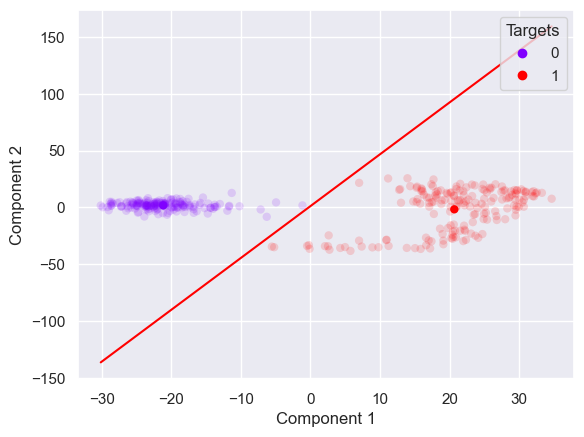

In [11]:
# Extra reference plot: class means and the decision boundary (PDF page 3).
# The red line is perpendicular to w_norm and passes through the midpoint
# of the class means; it is not the projection direction itself.
plt.figure()
plot_scatter(X, t, alpha=0.15, legend=False, w=w_norm)
plot_scatter(means, np.array([0, 1]), alpha=1)
plt.show()


### 1.4) Compute and plot the 1D projection of the data
Hint: You can use `seaborn.displot` for a nice visualisation

(360, 1)


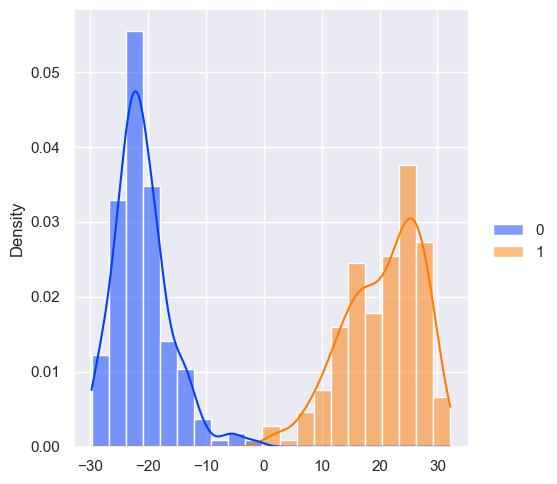

In [12]:
# Project each 2D sample onto the unit Fisher direction.
X_proj = (X @ w_norm).reshape(-1, 1)  # (N, 1)
print(X_proj.shape)

# Match the reference histogram: density, class colours, and smooth KDE curves.
# Flatten only for plotting: seaborn expects a 1D sequence of values.
g = sns.displot(
    x=X_proj.ravel(),
    hue=t,
    hue_order=[0, 1],
    kind="hist",
    bins=21,  # Match the binning in the sample PDF.
    stat="density",
    common_norm=True,
    kde=True,
    palette=sns.color_palette("bright", 2),
    height=5,
    aspect=1,
)
g.set_axis_labels("", "Density")
plt.show()


### 1.5) Compute the class separation of the projected values

In [13]:
# Project both class means onto the unit Fisher direction.
mean_0_proj = mean_0 @ w_norm # A single scalar for class 0
mean_1_proj = mean_1 @ w_norm # A single scalar for class 1

# Separation is the distance between the two projected means.
class_separation = np.abs(mean_1_proj - mean_0_proj)
print(class_separation)


41.5963134998038


## 2) Linear Discriminant Analysis (LDA)

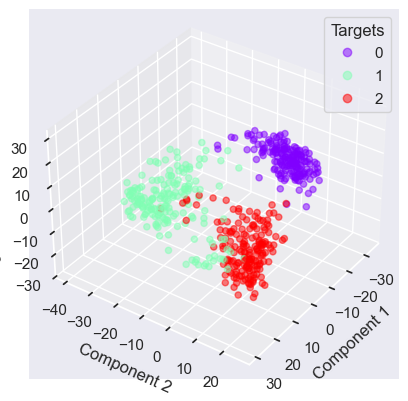

In [14]:
# Data
n_class = 3
digits = load_digits(n_class=n_class)
pca = PCA(n_components=3)
X = pca.fit_transform(digits.data)
t = digits.target

plot_scatter3d(X, t, view_point=(35,35))

### 2.1) Compute the within-class scatter matrix $\mathbf{S}_W$ and between-class scatter matrix $\mathbf{S}_B$
See section 4.1.6 in the textbook or Lecture 15 (slide 17)

In [15]:
# X shape: (N, 3), t shape: (N,); classes are labelled 0, 1 and 2
mask_0 = (t == 0)
class_0 = X[mask_0] # Data points in class 0, (# in class 0, 3)
mean_0 = np.mean(class_0, axis=0) # Average down the rows, (3,)

mask_1 = (t == 1)
class_1 = X[mask_1] # Data points in class 1, (# in class 1, 3)
mean_1 = np.mean(class_1, axis=0) # (3,)

mask_2 = (t == 2)
class_2 = X[mask_2] # Data points in class 2, (# in class 2, 3)
mean_2 = np.mean(class_2, axis=0) # (3,)

means = np.array([mean_0, mean_1, mean_2]) # (3, 3)
mean_tot = np.mean(X, axis=0) # Mean over ALL samples, (3,)

mean_0_reshape = np.reshape(mean_0, (1, 3)) # (1, 3)
mean_1_reshape = np.reshape(mean_1, (1, 3)) # (1, 3)
mean_2_reshape = np.reshape(mean_2, (1, 3)) # (1, 3)
mean_tot_reshape = np.reshape(mean_tot, (1, 3)) # (1, 3)

# Within-class scatter: sum the scatter around each class's own mean.
S_0 = (class_0 - mean_0_reshape).T @ (class_0 - mean_0_reshape)
S_1 = (class_1 - mean_1_reshape).T @ (class_1 - mean_1_reshape)
S_2 = (class_2 - mean_2_reshape).T @ (class_2 - mean_2_reshape)
S_w = S_0 + S_1 + S_2 # (3, 3)

# Between-class scatter: compare each class mean with the overall mean,
# weighting each outer product by the number of samples in that class.
N_0 = class_0.shape[0]
N_1 = class_1.shape[0]
N_2 = class_2.shape[0]

S_b = (
    N_0 * ((mean_0_reshape - mean_tot_reshape).T @ (mean_0_reshape - mean_tot_reshape))
    + N_1 * ((mean_1_reshape - mean_tot_reshape).T @ (mean_1_reshape - mean_tot_reshape))
    + N_2 * ((mean_2_reshape - mean_tot_reshape).T @ (mean_2_reshape - mean_tot_reshape))
) # (3, 3)

print("S_B = ", S_b)
print("S_W = ", S_w)


S_B =  [[168102.96379897 -19720.58431485 -19025.65777759]
 [-19720.58431485  63939.56119789 -18774.4552079 ]
 [-19025.65777759 -18774.4552079    9313.72206904]]
S_W =  [[27768.47732315 19720.58431485 19025.65777759]
 [19720.58431485 51486.18363134 18774.4552079 ]
 [19025.65777759 18774.4552079  56959.24503056]]


### 2.2) Compute the projection matrix $\mathbf{W}$
choose D'=2 (see lecture 15 slide 17 to understand D')

In [16]:
# S_w and S_b have shape (3, 3).
A = np.linalg.pinv(S_w) @ S_b
# A is generally not symmetric, so use eig rather than eigh.
eigenvalues, eigenvectors = np.linalg.eig(A)
eig_sort = np.argsort(eigenvalues)[::-1]
W = eigenvectors[:, eig_sort[:2]] # (3, 2): one direction per column
print(W)


[[ 0.91734684 -0.13270419]
 [-0.33360306 -0.82474716]
 [-0.21721826  0.54971058]]


### 2.3) Compute and plot the 2D projection of the data

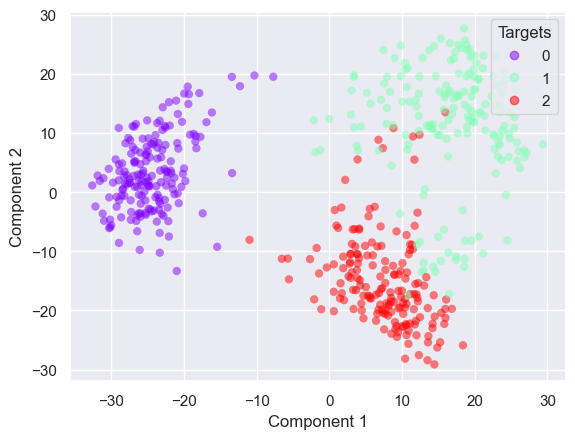

In [17]:
# Eigenvector signs are arbitrary. Choose the orientation shown in the PDF:
# class 0 is left of class 1; class 1 is above class 2.
if (mean_1 - mean_0) @ W[:, 0] < 0:
    W[:, 0] = -W[:, 0]
if (mean_1 - mean_2) @ W[:, 1] < 0:
    W[:, 1] = -W[:, 1]

X_proj = X @ W # (N, 3) @ (3, 2) -> (N, 2)
plt.figure()
plot_scatter(X_proj, t)
plt.show()


### 2.4) Compute and plot the 2D LDA projection of the original 64D data 

In [18]:
# Reuse the three-class digits dataset and labels from the start of part 2.
# Switch X from the 3D PCA representation to the original 64 pixel features.
X = digits.data


[178, 182, 177]


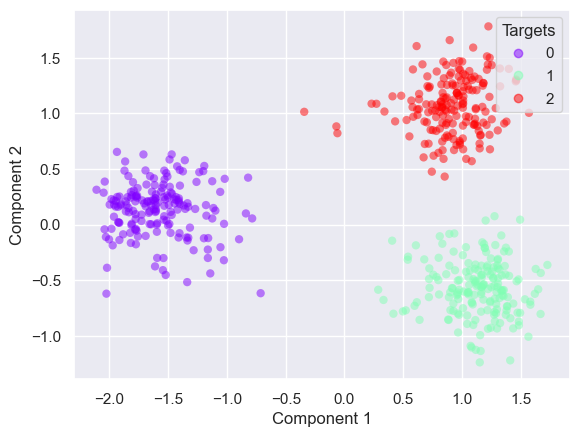

In [19]:
# Reuse t, mask_0, mask_1, mask_2 and N_0, N_1, N_2 from 2.1:
class_0 = X[mask_0] # Data points in class 0, (# in class 0, 64)
mean_0 = np.mean(class_0, axis=0) # Average down the rows, (64,)

class_1 = X[mask_1] # Data points in class 1, (# in class 1, 64)
mean_1 = np.mean(class_1, axis=0) # (64,)

class_2 = X[mask_2] # Data points in class 2, (# in class 2, 64)
mean_2 = np.mean(class_2, axis=0) # (64,)

means = np.array([mean_0, mean_1, mean_2]) # (3, 64)
mean_tot = np.mean(X, axis=0) # Mean over ALL samples, (64,)

mean_0_reshape = np.reshape(mean_0, (1, 64)) # (1, 64)
mean_1_reshape = np.reshape(mean_1, (1, 64)) # (1, 64)
mean_2_reshape = np.reshape(mean_2, (1, 64)) # (1, 64)
mean_tot_reshape = np.reshape(mean_tot, (1, 64)) # (1, 64)

# Within-class scatter: sum the scatter around each class's own mean.
S_0 = (class_0 - mean_0_reshape).T @ (class_0 - mean_0_reshape)
S_1 = (class_1 - mean_1_reshape).T @ (class_1 - mean_1_reshape)
S_2 = (class_2 - mean_2_reshape).T @ (class_2 - mean_2_reshape)
S_w = S_0 + S_1 + S_2 # (64, 64)

#compare each class mean with the overall mean,
# weighting each outer product by the number of samples in that class.
S_b = (
    N_0 * ((mean_0_reshape - mean_tot_reshape).T @ (mean_0_reshape - mean_tot_reshape))
    + N_1 * ((mean_1_reshape - mean_tot_reshape).T @ (mean_1_reshape - mean_tot_reshape))
    + N_2 * ((mean_2_reshape - mean_tot_reshape).T @ (mean_2_reshape - mean_tot_reshape))
) # (64, 64)


print([N_0, N_1, N_2]) # the class sizes from 2.1

# Eigenvalue decomposition:
A = np.linalg.pinv(S_w) @ S_b
eigenvalues, eigenvectors = np.linalg.eig(A)
# The leading eigenpairs are real
eig_sort = np.argsort(eigenvalues.real)[::-1]
W = np.real_if_close(eigenvectors[:, eig_sort[:2]]) # (64, 2)

# Match the reference orientation: class 0 left, class 2 above class 1.
if (mean_1 - mean_0) @ W[:, 0] < 0:
    W[:, 0] = -W[:, 0]
if (mean_2 - mean_1) @ W[:, 1] < 0:
    W[:, 1] = -W[:, 1]

X_proj = X @ W # (N, 64) @ (64, 2) -> (N, 2)
plt.figure()
plot_scatter(X_proj, t)
plt.show()


Comment on the general utility of the projection as compared to PCA

LDA uses class labels to find directions that separate class means while keeping within-class scatter small. PCA ignores labels and preserves directions of greatest overall variance, which need not separate the classes. Here, LDA using all 64 features produces more clearly separated groups than LDA after reduction to three PCA components, suggesting that the PCA reduction discarded useful class information. LDA is therefore useful for classification and labelled-data visualization, while PCA is useful for unsupervised compression.

_Note: Sections 1–2 above use material from Lecture 15 (FDA/LDA). The following section on constrained optimization requires Lecture 16 (Lagrangians and KKT conditions), the second lecture of Week 8._

# 3) Constrained Optimization
 
Consider the problem

minimize $f_{min}(x_1, x_2)$

subject to $ x_1 + x_2 \leq 4 
\quad \text{ and } \quad x_1 + 4x_2 = 5 
$
where $f_{min}(x_1, x_2) = (x_1 - 3)^2 + (x_2 - 2)^2$

## 3.1) Reformulate the problem as a canonical maximization problem
_Use the form described in the end of "Pattern Recognition and Machine Learning" Appendix E._

_NB: Appendix E writes the canonical **maximization** problem with inequality constraints in the form $h(x) \geq 0$ (with $\mu \geq 0$). This exercise's inequality is originally given as $x_1 + x_2 \leq 4$. To match Appendix E's form, define $h(x) = 4 - x_1 - x_2 \geq 0$ — a sign flip of the constraint, **not** an error in the book. Equivalently, if you prefer to keep $h(x) = x_1 + x_2 - 4 \leq 0$, you are using the standard convex-optimization convention from Lecture 16; just be consistent about the sign of $\mu$. Either choice gives the same optimum._

We multiply the objective by $-1$: maximizing its negative gives the same point as minimizing the original function.

$$
\max_{x_1,x_2}\;\tilde f(x_1,x_2)
=-\left[(x_1-3)^2+(x_2-2)^2\right].
$$

Subtract $5$ to write the equality with zero on the right:

$$
g(x_1,x_2)=x_1+4x_2-5=0.
$$

Rearrange the inequality so its left-hand side is nonnegative, as required by the textbook's maximization convention:

$$
h(x_1,x_2)=4-x_1-x_2\geq0.
$$

These are the same constraints as before; only their form has changed.

## 3.2) Write out the Lagrangian function
_Use Equation (E.12) in "Pattern Recognition and Machine Learning" Appendix E., and write out all variables_

The Lagrangian combines the objective and the two constraints:

$$
\mathcal L(x_1,x_2,\lambda,\mu)
=\tilde f(x_1,x_2)+\lambda g(x_1,x_2)+\mu h(x_1,x_2).
$$

Substituting our expressions gives

$$
\mathcal L
=-(x_1-3)^2-(x_2-2)^2
+\lambda(x_1+4x_2-5)
+\mu(4-x_1-x_2).
$$

Here $\lambda$ can have either sign, while $\mu\geq0$. The plus sign before $\mu h$ follows the textbook's maximization convention with $h\geq0$.

## 3.3) Compute the gradients with respects to $x_1, x_2$, lagrange multiplier $\lambda$ and the KKT multiplier $\mu$

Differentiate with respect to each variable:

$$
\frac{\partial\mathcal L}{\partial x_1}=-2(x_1-3)+\lambda-\mu,
\qquad
\frac{\partial\mathcal L}{\partial x_2}=-2(x_2-2)+4\lambda-\mu.
$$

$$
\frac{\partial\mathcal L}{\partial\lambda}=x_1+4x_2-5=g(x),
\qquad
\frac{\partial\mathcal L}{\partial\mu}=4-x_1-x_2=h(x).
$$

At the optimum, the two derivatives with respect to $x_1$ and $x_2$ are zero, and the equality constraint gives $g(x)=0$.

For the inequality, we use the KKT conditions:

$$
h(x)\geq0,\qquad \mu\geq0,\qquad \mu h(x)=0.
$$

We do **not** automatically set $\partial\mathcal L/\partial\mu=0$: that would force the inequality to be an equality. Instead, $\mu h(x)=0$ means that either the constraint is inactive ($h>0$, so $\mu=0$), or it is active ($h=0$).

### 3.4) Compute the optimum
_Hint: Set it up as a system of linear equations and solve it using Gaussian Elimination (e.g. using `scipy.linalg.solve`)._

Here $\tilde{f} = -f_{min}$ is the maximization objective from step 3.1, and $h(x) = 4 - x_1 - x_2 \geq 0$.

Follow these steps:

1. **Assume the inequality constraint \( h(x) \) is inactive.**  
   - Set its KKT multiplier to zero (\( \mu = 0 \)).  
   - Include only the equality constraint \( g(x) = 0 \) in your formulation.  
   - Construct the system of equations from the KKT conditions:  
     \[
     \nabla \tilde{f}(x) + \lambda \nabla g(x) = 0, \quad g(x) = 0
     \]
   - Solve for \( x_1, x_2, \lambda \) using `scipy.linalg.solve`.

2. **Check the inequality constraint.**  
   - Evaluate \( h(x_1, x_2) \).  
   - If \( h(x_1, x_2) > 0 \), the constraint is inactive — keep this as your final solution.

3. **If the inequality is violated** (\( h(x_1, x_2) < 0 \)):  
   - Reformulate the problem assuming \( h(x) \) is **active** (\( h(x) = 0 \)).  
   - Include both constraints in the Lagrangian:  
     \[
     \mathcal{L}(x_1, x_2, \lambda, \mu) = \tilde{f}(x_1, x_2) + \lambda g(x_1, x_2) + \mu h(x_1, x_2)
     \]
   - Construct the corresponding system of equations:
     \[
     \nabla \tilde{f}(x) + \lambda \nabla g(x) + \mu \nabla h(x) = 0, \quad g(x) = 0, \quad h(x) = 0
     \]
   - Solve for \( x_1, x_2, \lambda, \mu \) using `scipy.linalg.solve`.

_The correct optimum is the solution that satisfies all constraints and yields the lowest \( f_{min}(x) \)._


**Step 1: try an inactive inequality.** Set $\mu=0$. Setting the derivatives to zero and including the equality gives

$$
-2x_1+\lambda=-6,\qquad
-2x_2+4\lambda=-4,\qquad
x_1+4x_2=5.
$$

Write this as $A\mathbf z=b$, with $\mathbf z=(x_1,x_2,\lambda)^T$:

$$
\begin{bmatrix}
-2&0&1\\
0&-2&4\\
1&4&0
\end{bmatrix}
\begin{bmatrix}x_1\\x_2\\\lambda\end{bmatrix}
=
\begin{bmatrix}-6\\-4\\5\end{bmatrix}.
$$

**Step 2: check the inequality.** Compute $h=4-x_1-x_2$. If $h\geq0$, this candidate is feasible and $\mu=0$ satisfies complementary slackness. If $h>0$, the inequality is inactive; if $h=0$, it is active with a zero multiplier.

**Step 3: if the candidate violates the inequality, try the active case.** Set $h=0$ and solve for $(x_1,x_2,\lambda,\mu)$:

$$
\begin{bmatrix}
-2&0&1&-1\\
0&-2&4&-1\\
1&4&0&0\\
-1&-1&0&0
\end{bmatrix}
\begin{bmatrix}x_1\\x_2\\\lambda\\\mu\end{bmatrix}
=
\begin{bmatrix}-6\\-4\\5\\-4\end{bmatrix}.
$$

Check that $\mu\geq0$ as well as feasibility, stationarity, and $\mu h=0$. The code uses a small tolerance for floating-point rounding.

The original objective is strictly convex and the constraints are affine. Therefore, a point satisfying these KKT conditions is the unique global minimum.

In [20]:
# 1) Assume the inequality is inactive: mu = 0.
# Unknowns are [x_1, x_2, lambda]. Each row is one equation.
A = np.array([
    [-2,  0, 1],
    [ 0, -2, 4],
    [ 1,  4, 0]
], dtype=float)
b = np.array([-6, -4, 5], dtype=float)

solution = scipy.linalg.solve(A, b)
x_1, x_2, lambda_ = solution 
mu = 0.0

# 2) Check whether the inequality is satisfied.
h = 4 - x_1 - x_2
tolerance = 1e-10

# 3) If the inequality is violated, solve again assuming it is active.
if h < -tolerance:
    # Unknowns are now [x_1, x_2, lambda, mu]; the last row imposes h = 0.
    A = np.array([
        [-2,  0, 1, -1],
        [ 0, -2, 4, -1],
        [ 1,  4, 0,  0],
        [-1, -1, 0,  0]
    ], dtype=float)
    b = np.array([-6, -4, 5, -4], dtype=float)

    solution = scipy.linalg.solve(A, b)
    x_1, x_2, lambda_, mu = solution

# 4) Evaluate the ORIGINAL minimization objective and both constraints.
f_min = (x_1 - 3)**2 + (x_2 - 2)**2
g = x_1 + 4*x_2 - 5
h = 4 - x_1 - x_2

# 5) Verify stationarity, feasibility and complementary slackness.
grad_x_1 = -2*(x_1 - 3) + lambda_ - mu
grad_x_2 = -2*(x_2 - 2) + 4*lambda_ - mu

stationarity = np.allclose([grad_x_1, grad_x_2], 0, atol=tolerance)
feasibility = np.isclose(g, 0, atol=tolerance) and h >= -tolerance
multiplier_sign = mu >= -tolerance
complementary_slackness = np.isclose(mu*h, 0, atol=tolerance)

if stationarity and feasibility and multiplier_sign and complementary_slackness:
    print("KKT conditions are fulfilled.")
else:
    raise ValueError("KKT conditions are NOT fulfilled; check the candidate.")

print("x_1 =", x_1)
print("x_2 =", x_2)
print("lambda =", lambda_)
print("mu =", mu)
print("min f(x) =", f_min)
print("g(x) =", g)
print("h(x) =", h)

if h > tolerance:
    print("The inequality is inactive: x_1 + x_2 < 4.")
else:
    print("The inequality is active: x_1 + x_2 = 4.")


KKT conditions are fulfilled.
x_1 = 2.6470588235294117
x_2 = 0.5882352941176471
lambda = -0.7058823529411764
mu = 0.0
min f(x) = 2.117647058823529
g(x) = 0.0
h(x) = 0.7647058823529412
The inequality is inactive: x_1 + x_2 < 4.
